In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Retail Sales Analysis Project Started!")

Retail Sales Analysis Project Started!


In [ ]:
import pandas as pd

df = pd.read_csv('/content/OnlineRetail.csv', encoding='ISO-8859-1')

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
# Check dataset size
print("Rows and Columns:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns)

# Check dataset information
print("\nDataset Information:")
df.info()

Rows and Columns: (541909, 8)

Column Names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
# Check missing values in each column
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [ ]:
# Remove rows with missing values
df = df.dropna()

# Check missing values again
print(df.isnull().sum())

# Check updated dataset size
print("Updated dataset shape:", df.shape)

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
Updated dataset shape: (406829, 8)


In [ ]:
# Check duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 5225


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check duplicates again
print("Duplicates after removal:", df.duplicated().sum())

# Check updated dataset size
print("Final dataset shape:", df.shape)

Duplicates after removal: 0
Final dataset shape: (401604, 8)


In [ ]:
# Statistical summary of numerical columns
display(df.describe())

,Quantity,UnitPrice,CustomerID
count,401604.000000,401604.000000,401604.000000
mean,12.183273,3.474064,15281.160818
std,250.283037,69.764035,1714.006089
min,-80995.000000,0.000000,12346.000000
25%,2.000000,1.250000,13939.000000
50%,5.000000,1.950000,15145.000000
75%,12.000000,3.750000,16784.000000
max,80995.000000,38970.000000,18287.000000


In [ ]:
# Calculate total sales
df['TotalSales'] = df['Quantity'] * df['UnitPrice']

# Display first 5 records
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


In [ ]:
# Calculate total revenue
total_revenue = df['TotalSales'].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 8278519.424


In [ ]:
# Calculate sales by country
country_sales = df.groupby('Country')['TotalSales'].sum()

# Sort sales from highest to lowest
country_sales = country_sales.sort_values(ascending=False)

# Display top 10 countries
print(country_sales.head(10))

Country
United Kingdom    6747156.154
Netherlands        284661.540
EIRE               250001.780
Germany            221509.470
France             196626.050
Australia          137009.770
Switzerland         55739.400
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: TotalSales, dtype: float64


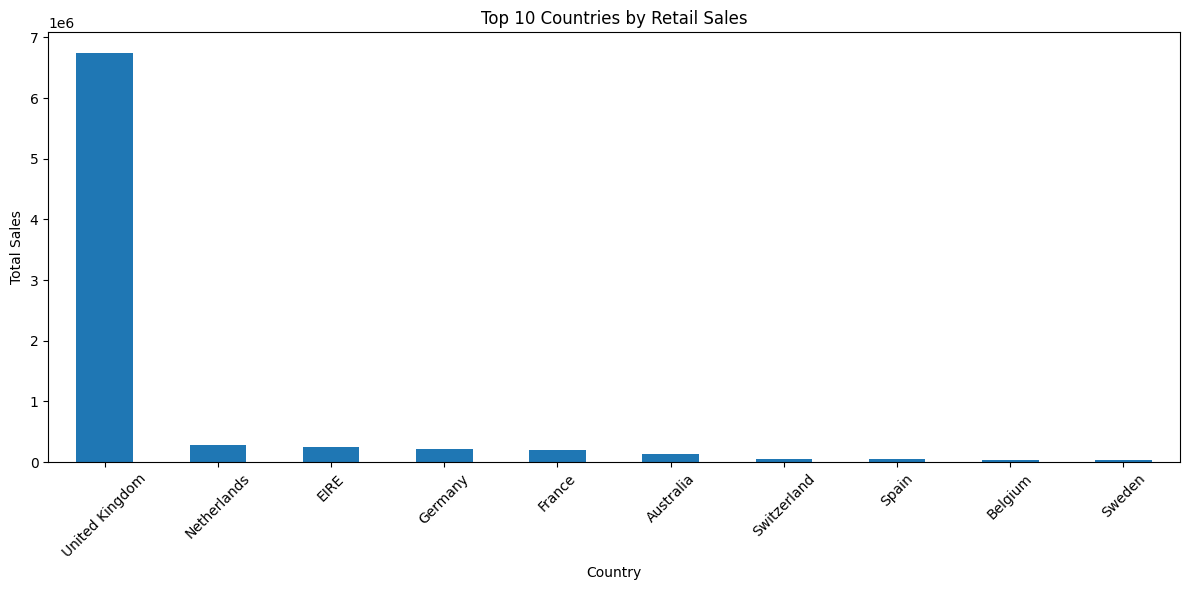

In [ ]:
import matplotlib.pyplot as plt

# Get top 10 countries
top_countries = country_sales.head(10)

# Create bar chart
plt.figure(figsize=(12, 6))
top_countries.plot(kind='bar')

plt.title('Top 10 Countries by Retail Sales')
plt.xlabel('Country')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Convert InvoiceDate into date format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract month and year
df['Month'] = df['InvoiceDate'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = df.groupby('Month')['TotalSales'].sum()

# Display monthly sales
print(monthly_sales)

Month
2010-12     552372.860
2011-01     473731.900
2011-02     435534.070
2011-03     578576.210
2011-04     425222.671
2011-05     647011.670
2011-06     606862.520
2011-07     573112.321
2011-08     615078.090
2011-09     929356.232
2011-10     973306.380
2011-11    1126815.070
2011-12     341539.430
Freq: M, Name: TotalSales, dtype: float64


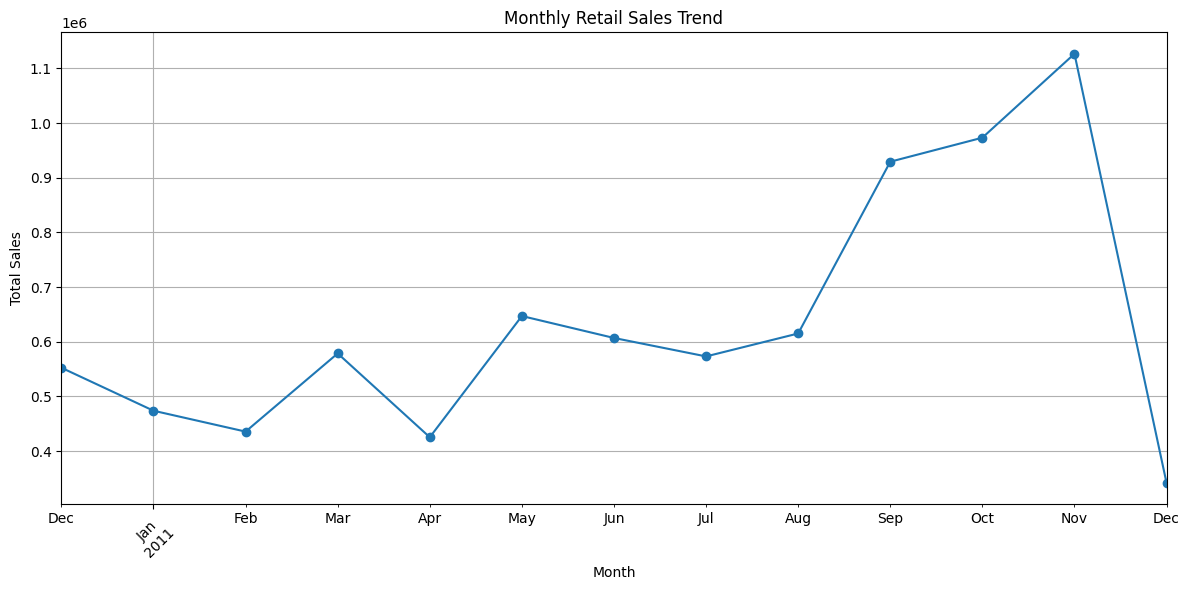

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate sales by product
product_sales = df.groupby('Description')['TotalSales'].sum()

# Find top 10 products
top_products = product_sales.sort_values(ascending=False).head(10)

# Display results
print(top_products)

Description
REGENCY CAKESTAND 3 TIER              132567.70
WHITE HANGING HEART T-LIGHT HOLDER     93767.80
JUMBO BAG RED RETROSPOT                83056.52
PARTY BUNTING                          67628.43
POSTAGE                                66710.24
ASSORTED COLOUR BIRD ORNAMENT          56331.91
RABBIT NIGHT LIGHT                     51042.84
CHILLI LIGHTS                          45915.41
PAPER CHAIN KIT 50'S CHRISTMAS         41423.78
PICNIC BASKET WICKER 60 PIECES         39619.50
Name: TotalSales, dtype: float64


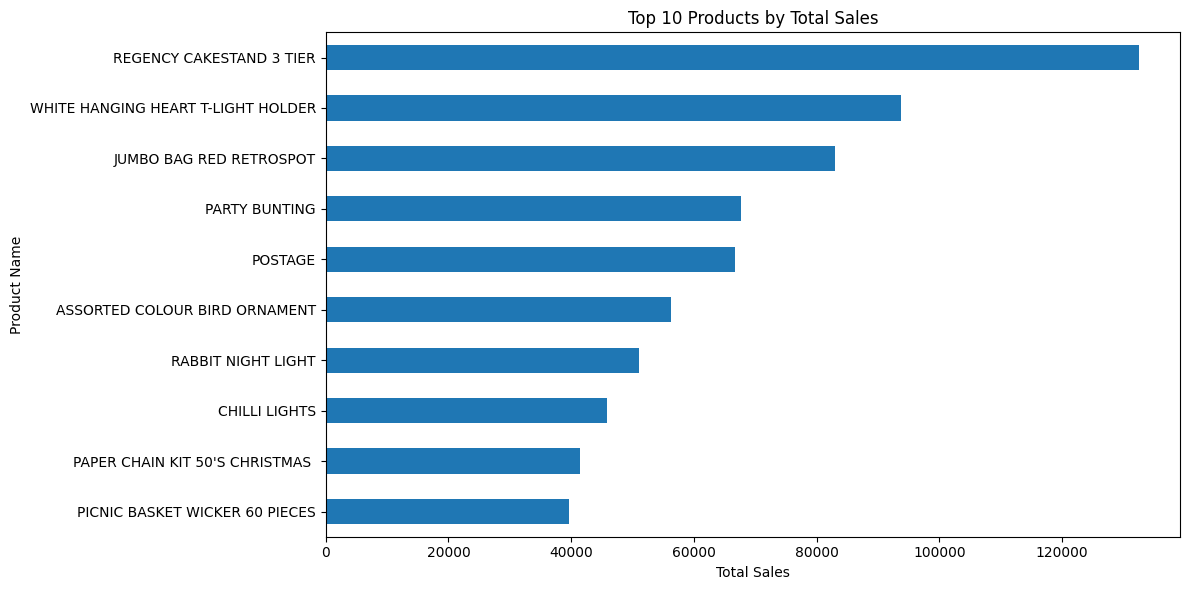

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')

plt.tight_layout()
plt.show()

In [ ]:
# Calculate sales by customer
customer_sales = df.groupby('CustomerID')['TotalSales'].sum()

# Find top 10 customers
top_customers = customer_sales.sort_values(ascending=False).head(10)

# Display results
print(top_customers)

CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187322.17
14911.0    132458.73
12415.0    123725.45
14156.0    113214.59
17511.0     88125.38
16684.0     65892.08
13694.0     62690.54
15311.0     59284.19
Name: TotalSales, dtype: float64


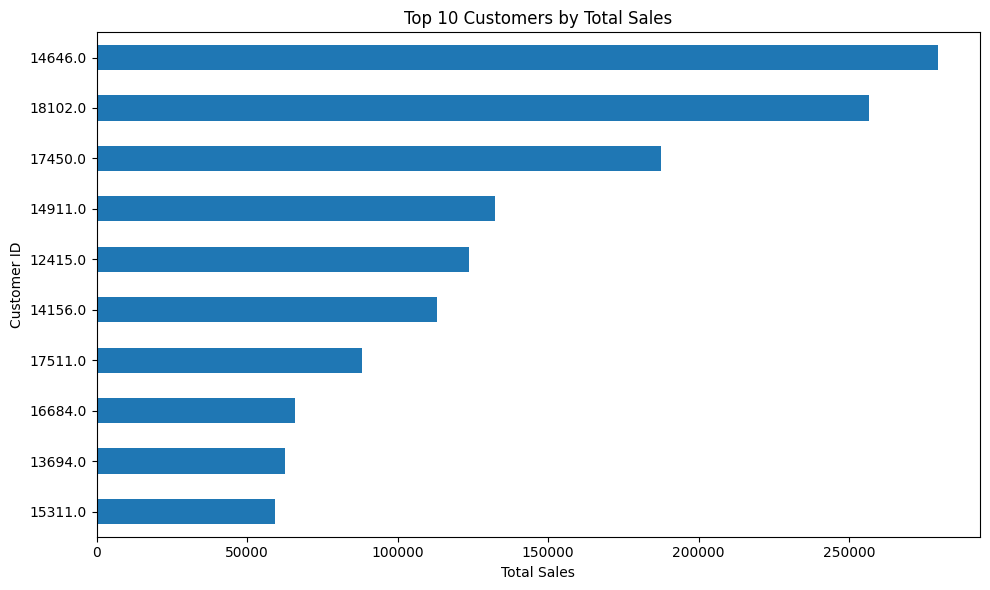

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

top_customers.sort_values().plot(kind='barh')

plt.title('Top 10 Customers by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Customer ID')

plt.tight_layout()
plt.show()

In [ ]:
# Key sales insights

print("Total Revenue:", df['TotalSales'].sum())

print("Total Orders:", df['InvoiceNo'].nunique())

print("Total Customers:", df['CustomerID'].nunique())

print("Total Products:", df['Description'].nunique())

print("Number of Countries:", df['Country'].nunique())

Total Revenue: 8278519.424
Total Orders: 22190
Total Customers: 4372
Total Products: 3896
Number of Countries: 37


In [ ]:
# Save the cleaned dataset
df.to_csv('Cleaned_OnlineRetail.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'Cleaned_OnlineRetail.csv', 'OnlineRetail.csv', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv('/content/Cleaned_OnlineRetail.csv', encoding='ISO-8859-1')

print("Dataset loaded successfully!")
display(df.head())

print("Dataset shape:", df.shape)

Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


Dataset shape: (19763, 10)


In [ ]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19763 entries, 0 to 19762
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    19763 non-null  object 
 1   StockCode    19762 non-null  object 
 2   Description  19762 non-null  object 
 3   Quantity     19762 non-null  float64
 4   InvoiceDate  19762 non-null  object 
 5   UnitPrice    19762 non-null  float64
 6   CustomerID   19762 non-null  float64
 7   Country      19762 non-null  object 
 8   TotalSales   19762 non-null  float64
 9   Month        19762 non-null  object 
dtypes: float64(4), object(6)
memory usage: 1.5+ MB

Missing Values:
InvoiceNo      0
StockCode      1
Description    1
Quantity       1
InvoiceDate    1
UnitPrice      1
CustomerID     1
Country        1
TotalSales     1
Month          1
dtype: int64

Duplicate Records:
0

Statistical Summary:


,Quantity,UnitPrice,CustomerID,TotalSales
count,19762.000000,19762.000000,19762.000000,19762.000000
mean,10.045694,3.139106,15566.456229,20.147346
std,80.206921,5.352673,1735.818663,82.620385
min,-9360.000000,0.000000,12347.000000,-1188.000000
25%,1.000000,1.250000,14298.000000,3.750000
50%,4.000000,2.100000,15574.000000,10.080000
75%,12.000000,3.750000,17198.000000,17.850000
max,2880.000000,295.000000,18269.000000,3828.000000


In [ ]:
# Remove rows containing missing values
df = df.dropna()

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

# Check updated dataset size
print("\nUpdated dataset shape:", df.shape)

Missing values after cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalSales     0
Month          0
dtype: int64

Updated dataset shape: (19762, 10)


In [ ]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'archive (1).zip', 'Cleaned_OnlineRetail.csv', 'sample_data']


In [ ]:
import zipfile
import os

zip_path = '/content/archive (1).zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/customer_data')

print("ZIP file extracted successfully!")

print(os.listdir('/content/customer_data'))

ZIP file extracted successfully!
['marketing_campaign.csv']


In [ ]:
import pandas as pd

df = pd.read_csv(
    '/content/customer_data/marketing_campaign.csv',
    sep='\t'
)

print("Customer dataset loaded successfully!")

display(df.head())

print("Dataset shape:", df.shape)

Customer dataset loaded successfully!


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


Dataset shape: (2240, 29)


In [ ]:
# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [ ]:
# Fill missing income values with median income
df['Income'] = df['Income'].fillna(df['Income'].median())

# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print("Missing values after cleaning:")
print(df.isnull().sum().sum())

# Check final dataset shape
print("\nFinal dataset shape:", df.shape)

print("\nData cleaning completed successfully!")

Missing values after cleaning:
0

Final dataset shape: (2240, 29)

Data cleaning completed successfully!


In [ ]:
# Calculate total spending by each customer
df['Total_Spending'] = (
    df['MntWines'] +
    df['MntFruits'] +
    df['MntMeatProducts'] +
    df['MntFishProducts'] +
    df['MntSweetProducts'] +
    df['MntGoldProds']
)

# Calculate total purchases
df['Total_Purchases'] = (
    df['NumWebPurchases'] +
    df['NumCatalogPurchases'] +
    df['NumStorePurchases']
)

# Display customer spending
display(df[['ID', 'Income', 'Total_Spending', 'Total_Purchases']].head())

print("Customer spending calculated successfully!")

,ID,Income,Total_Spending,Total_Purchases
0,5524,58138.0,1617,22
1,2174,46344.0,27,4
2,4141,71613.0,776,20
3,6182,26646.0,53,6
4,5324,58293.0,422,14


Customer spending calculated successfully!


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select features for customer segmentation
X = df[['Income', 'Total_Spending']]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Customer data scaled successfully!")
print("Scaled data shape:", X_scaled.shape)

Customer data scaled successfully!
Scaled data shape: (2240, 2)


In [ ]:
# Apply K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df['Customer_Cluster'] = kmeans.fit_predict(X_scaled)

# Count customers in each group
print("Customer Groups:")
print(df['Customer_Cluster'].value_counts().sort_index())

print("\nCustomer segmentation completed successfully!")

Customer Groups:
Customer_Cluster
0     650
1     456
2    1133
3       1
Name: count, dtype: int64

Customer segmentation completed successfully!


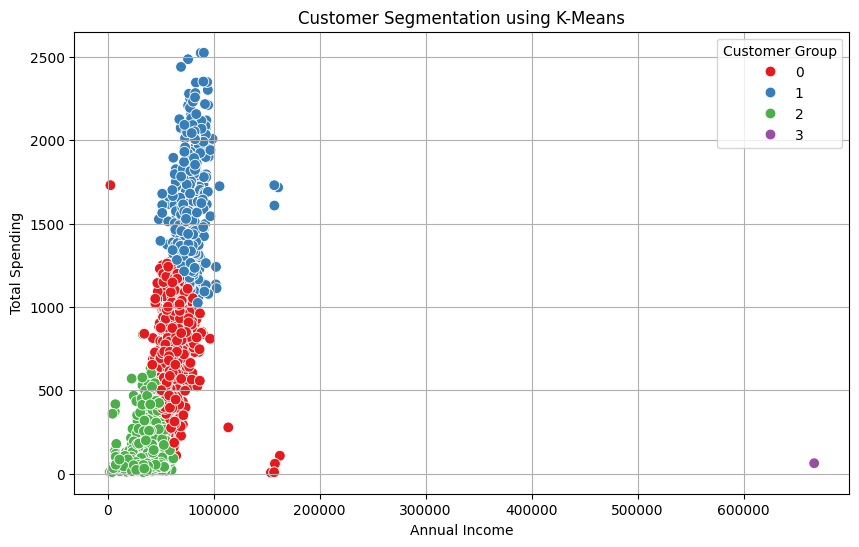

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Income',
    y='Total_Spending',
    hue='Customer_Cluster',
    palette='Set1',
    s=60
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Annual Income')
plt.ylabel('Total Spending')
plt.legend(title='Customer Group')
plt.grid(True)
plt.show()

In [ ]:
# Analyze each customer group
cluster_summary = df.groupby('Customer_Cluster').agg({
    'Income': 'mean',
    'Total_Spending': 'mean',
    'Total_Purchases': 'mean',
    'ID': 'count'
}).round(2)

cluster_summary.rename(columns={
    'ID': 'Number_of_Customers'
}, inplace=True)

display(cluster_summary)

,Income,Total_Spending,Total_Purchases,Number_of_Customers
Customer_Cluster,,,,
0,63393.07,767.22,17.85,650
1,77983.12,1570.64,19.85,456
2,34934.34,125.35,6.55,1133
3,666666.00,62.00,7.00,1


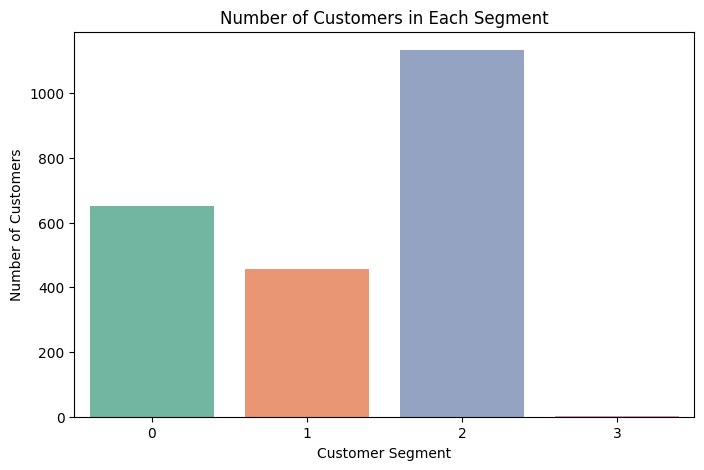

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Customer_Cluster',
    hue='Customer_Cluster',
    palette='Set2',
    legend=False
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.show()

In [ ]:
plt.savefig('customer_segment_count.png', bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

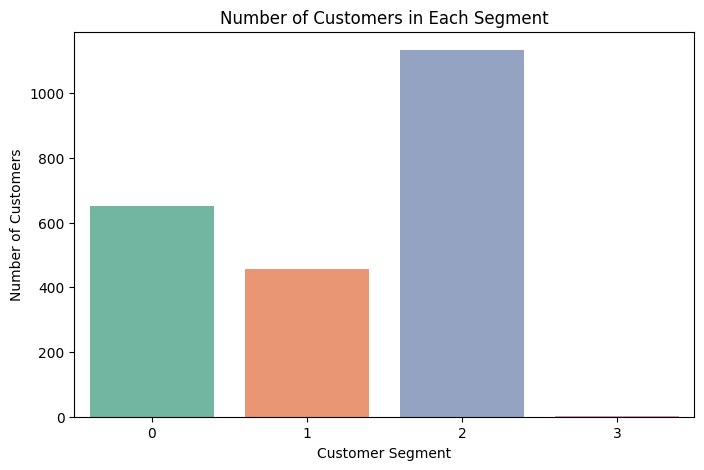

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Customer_Cluster',
    hue='Customer_Cluster',
    palette='Set2',
    legend=False
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')

plt.savefig('customer_segment_count.png', bbox_inches='tight')
plt.show()